## Where counties depart from the profile

Notebook 4 left four terms that line up with Kaiser share across offered counties: log population, the uninsured rate, unemployment, and the benchmark Silver premium. This notebook uses that profile to point somewhere.

1. Which offered counties sit well above or below the share their profile implies, and whether a ZIP-limited service area or a large market sits behind the gap.
2. Whether share moves when a county's own conditions change, or only differs between counties.
3. How Monterey's first year compares with Santa Cruz, the one other county Kaiser opened during these years.
4. Which counties outside the footprint resemble counties inside it.

None of this is a recommendation. Each section names counties or questions worth a closer look.


In [1]:
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from IPython.display import HTML, Markdown, display

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 11,
})

FOUR_FORMULA = (
    "kp_market_share ~ log_population + uninsured_rate + unemployment_rate "
    "+ benchmark_silver_premium"
)
FOUR_TERMS = ["log_population", "uninsured_rate", "unemployment_rate", "benchmark_silver_premium"]
TERM_LABELS = {
    "log_population": ("Population", "per doubling", np.log(2) * 100),
    "uninsured_rate": ("Uninsured rate", "per percentage point", 100),
    "unemployment_rate": ("Unemployment rate", "per percentage point", 100),
    "benchmark_silver_premium": ("Benchmark Silver premium", "per $10", 1000),
}


def format_p(p_value):
    if p_value < 0.001:
        return "<0.001"
    return f"{p_value:.3f}"


def short_county(name):
    return name.replace(" County", "")


con = duckdb.connect("../data/processed/analysis.duckdb", read_only=True)
market = con.sql("select * from main_marts.mart_cty_yr_market").df()
performance = con.sql("select * from main_marts.mart_cty_yr_performance").df()
socioeconomic = con.sql("select * from main_marts.mart_cty_yr_socioeconomic").df()
footprint = con.sql("""
    select
        year,
        county_fips,
        bool_and(coalesce(is_partial_county, false)) as partial_county
    from main_staging.stg_cms_service_areas
    where issuer_id = '40513'
      and service_area_id = 'CAS002'
    group by 1, 2
""").df()

panel = (
    market.merge(performance, on=["county_fips", "year"], how="left", suffixes=("", "_performance"))
    .merge(socioeconomic, on=["county_fips", "year"], how="left", suffixes=("", "_socio"))
    .merge(footprint, on=["county_fips", "year"], how="left")
)
panel["county"] = panel["county_name"].map(short_county)
panel["log_population"] = np.log(panel["population_total"])

offered = panel[panel["kp_offered"] & panel["year"].between(2016, 2024)].copy()
measure_cols = [
    "kp_market_share",
    "population_total",
    "uninsured_rate",
    "unemployment_rate",
    "benchmark_silver_premium",
]
county = offered.groupby(["county_fips", "county"], as_index=False)[measure_cols].mean()
county["log_population"] = np.log(county["population_total"])
sample = county.dropna(subset=measure_cols).copy()
profile_model = smf.ols(FOUR_FORMULA, data=sample).fit(cov_type="HC1")
residual_sd = float(np.sqrt(profile_model.mse_resid))
SOUTHERN = ["Imperial", "Kern", "Orange", "Riverside", "San Bernardino", "San Diego", "Ventura"]
sample["southern"] = sample["county"].isin(SOUTHERN).astype(int)
regional_model = smf.ols(FOUR_FORMULA + " + southern", data=sample).fit(cov_type="HC1")
regional_sd = float(np.sqrt(regional_model.mse_resid))

display(Markdown(
    f"The four-term profile is refit on **{len(sample)} counties** "
    f"(2016–2024 averages; Los Angeles and Monterey are out, as in notebook 4). "
    f"Adjusted R² is **{profile_model.rsquared_adj:.2f}**. "
    f"The residual standard error is **{residual_sd * 100:.1f}** percentage points of share. "
    f"With the Southern California indicator from notebook 4 added, adjusted R² is "
    f"**{regional_model.rsquared_adj:.2f}** and the residual standard error is **{regional_sd * 100:.1f}** points."
))


The four-term profile is refit on **31 counties** (2016–2024 averages; Los Angeles and Monterey are out, as in notebook 4). Adjusted R² is **0.60**. The residual standard error is **16.4** percentage points of share. With the Southern California indicator from notebook 4 added, adjusted R² is **0.63** and the residual standard error is **15.6** points.

## Counties above and below their profile

A county's expected share is what the four-term profile implies for its 2016–2024 average conditions. The departure is actual average share minus that expectation. Counties at least one residual standard error away are flagged.

Two facts are attached to each county. Footprint says whether Kaiser's 2025 individual-market service area covers the whole county or only some ZIP codes. Members at 2025 size multiplies the departure by the county's 2025 Covered California enrollment, which shows what the same gap is worth in a large market against a small one. It is a scale for comparison, not members Kaiser could add.

A second departure, with region, adds the Southern California indicator from notebook 4, so a county is compared with counties on its own side of Kaiser's Northern and Southern California split. A flag that holds under both is less likely to be the regional gap.


county,flag,footprint,share_2016_2024,expected,departure_pp,with_region_pp,share_2025,market_2025,members_at_2025_size
Sutter,Below profile,Some ZIP codes,2%,27%,-25.3,-26.2,2%,"6,240","-1,579"
Orange,Below profile,Whole county,18%,40%,-22.6,-16.2,25%,"182,270","-41,153"
San Francisco,Below profile,Whole county,53%,73%,-20.2,-19.5,58%,"38,740","-7,837"
Santa Clara,Below profile,Some ZIP codes,49%,69%,-19.7,-23.4,55%,"80,980","-15,921"
Amador,Below profile,Some ZIP codes,20%,40%,-19.6,-13.8,23%,"1,940",-380
Tulare,Below profile,Some ZIP codes,2%,20%,-18.0,-27.3,3%,"11,800","-2,127"
San Diego,,Some ZIP codes,24%,38%,-14.5,-8.9,20%,"149,310","-21,600"
Mariposa,,Some ZIP codes,2%,15%,-12.6,-9.5,3%,980,-123
Ventura,,Some ZIP codes,26%,38%,-12.0,-0.4,30%,"45,980","-5,511"
El Dorado,,Some ZIP codes,41%,48%,-6.7,-5.7,37%,"10,470",-699


**6 counties** sit at least 16 points below their profile: Sutter, Orange, San Francisco, Santa Clara, Amador, and Tulare. **5 counties** sit at least that far above it: Stanislaus, Madera, Napa, Solano, and San Joaquin. The median departure is **+3.2** points for whole-county service areas (10 counties) and **-0.5** for ZIP-limited ones (21 counties). A ZIP-limited footprint does not by itself account for the shortfalls: Orange and San Francisco are whole-county. In members, the largest shortfalls at 2025 market size are Orange (-41,153), Santa Clara (-15,921), San Francisco (-7,837). With region held constant, Sutter, Orange, San Francisco, Santa Clara, Tulare, Napa, Solano, and San Joaquin stay at least 16 points from their profile in the same direction. Amador, Stanislaus, and Madera fall inside that band. Orange is **-16.2** points with region, **-29,600** members at 2025 size.

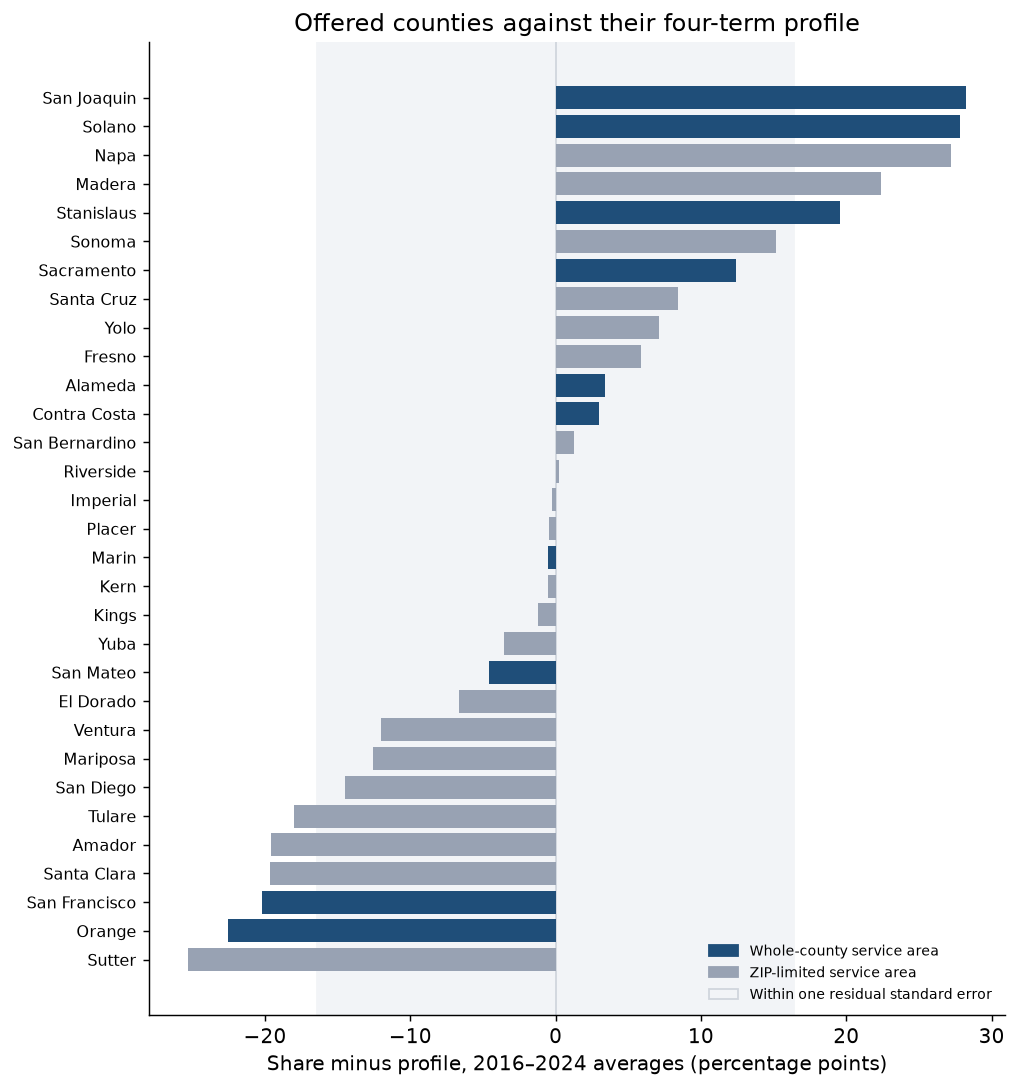

In [2]:
departures = sample[["county_fips", "county", "kp_market_share"]].copy()
departures["expected_share"] = profile_model.fittedvalues.to_numpy()
departures["departure_pp"] = profile_model.resid.to_numpy() * 100
departures["departure_with_region_pp"] = regional_model.resid.to_numpy() * 100
year_2025 = panel.loc[panel["year"] == 2025, [
    "county_fips", "partial_county", "kp_market_share", "total_marketplace_enrollment",
]].rename(columns={"kp_market_share": "share_2025", "total_marketplace_enrollment": "market_2025"})
departures = departures.merge(year_2025, on="county_fips", how="left")
departures["footprint"] = np.where(departures["partial_county"], "Some ZIP codes", "Whole county")
departures["members_at_2025_size"] = departures["departure_pp"] / 100 * departures["market_2025"]
departures["flag"] = np.select(
    [
        departures["departure_pp"] <= -residual_sd * 100,
        departures["departure_pp"] >= residual_sd * 100,
    ],
    ["Below profile", "Above profile"],
    default="",
)
departures["holds_with_region"] = (
    departures["flag"].ne("")
    & (departures["departure_with_region_pp"].abs() >= regional_sd * 100)
    & (np.sign(departures["departure_with_region_pp"]) == np.sign(departures["departure_pp"]))
)
departures = departures.sort_values("departure_pp").reset_index(drop=True)

departure_view = pd.DataFrame({
    "county": departures["county"],
    "flag": departures["flag"],
    "footprint": departures["footprint"],
    "share_2016_2024": (departures["kp_market_share"] * 100).map(lambda value: f"{value:.0f}%"),
    "expected": (departures["expected_share"] * 100).map(lambda value: f"{value:.0f}%"),
    "departure_pp": departures["departure_pp"].map(lambda value: f"{value:+.1f}"),
    "with_region_pp": departures["departure_with_region_pp"].map(lambda value: f"{value:+.1f}"),
    "share_2025": (departures["share_2025"] * 100).map(lambda value: f"{value:.0f}%"),
    "market_2025": departures["market_2025"].map(lambda value: f"{value:,.0f}"),
    "members_at_2025_size": departures["members_at_2025_size"].map(lambda value: f"{value:+,.0f}"),
})
display(HTML(departure_view.to_html(index=False)))

below = departures[departures["flag"].eq("Below profile")]
above = departures[departures["flag"].eq("Above profile")]
by_footprint = departures.groupby("footprint")["departure_pp"].agg(["count", "median"])
largest_below = below.sort_values("members_at_2025_size").head(3)


def county_list(frame):
    names = frame["county"].tolist()
    if len(names) <= 2:
        return " and ".join(names)
    return ", ".join(names[:-1]) + f", and {names[-1]}"


display(Markdown(
    f"**{len(below)} counties** sit at least {residual_sd * 100:.0f} points below their profile: "
    f"{county_list(below)}. "
    f"**{len(above)} counties** sit at least that far above it: {county_list(above)}. "
    f"The median departure is **{by_footprint.loc['Whole county', 'median']:+.1f}** points for "
    f"whole-county service areas ({int(by_footprint.loc['Whole county', 'count'])} counties) and "
    f"**{by_footprint.loc['Some ZIP codes', 'median']:+.1f}** for ZIP-limited ones "
    f"({int(by_footprint.loc['Some ZIP codes', 'count'])} counties). "
    f"A ZIP-limited footprint does not by itself account for the shortfalls: "
    f"{county_list(below[below['footprint'].eq('Whole county')])} "
    f"{'is' if (below['footprint'].eq('Whole county')).sum() == 1 else 'are'} whole-county. "
    "In members, the largest shortfalls at 2025 market size are "
    + ", ".join(
        f"{row.county} ({row.members_at_2025_size:,.0f})" for row in largest_below.itertuples()
    )
    + ". "
    f"With region held constant, {county_list(departures[departures['holds_with_region']])} stay at least "
    f"{regional_sd * 100:.0f} points from their profile in the same direction. "
    f"{county_list(departures[departures['flag'].ne('') & ~departures['holds_with_region']])} fall inside that band. "
    + " ".join(
        f"{row.county} is **{row.departure_with_region_pp:+.1f}** points with region, "
        f"**{row.departure_with_region_pp / 100 * row.market_2025:+,.0f}** members at 2025 size."
        for row in largest_below.head(1).itertuples()
    )
))

fig, ax = plt.subplots(figsize=(8, 8.5))
positions = np.arange(len(departures))
colors = np.where(departures["footprint"].eq("Whole county"), "#1f4e79", "#98a2b3")
ax.axvspan(-residual_sd * 100, residual_sd * 100, color="#f2f4f7", zorder=0)
ax.axvline(0, color="#d0d5dd", linewidth=1)
ax.barh(positions, departures["departure_pp"], color=colors, zorder=2)
ax.set_yticks(positions)
ax.set_yticklabels(departures["county"], fontsize=9)
ax.set_xlabel("Share minus profile, 2016–2024 averages (percentage points)")
ax.set_title("Offered counties against their four-term profile")
handles = [
    plt.Rectangle((0, 0), 1, 1, color="#1f4e79"),
    plt.Rectangle((0, 0), 1, 1, color="#98a2b3"),
    plt.Rectangle((0, 0), 1, 1, facecolor="#f2f4f7", edgecolor="#d0d5dd"),
]
ax.legend(
    handles,
    ["Whole-county service area", "ZIP-limited service area", "Within one residual standard error"],
    loc="lower right",
    fontsize=8,
    frameon=False,
)
fig.tight_layout()


## The profile on a map

The left map is Kaiser's 2025 share in each offered county. The right map is the departure from the profile in the section above, with hatching for a ZIP-limited service area and labels for the flagged counties. Los Angeles and Monterey are offered but outside the profile fit: Los Angeles has no benchmark premium, and Monterey opened in 2025. County boundaries are the Census Bureau's 2023 cartographic boundary file.

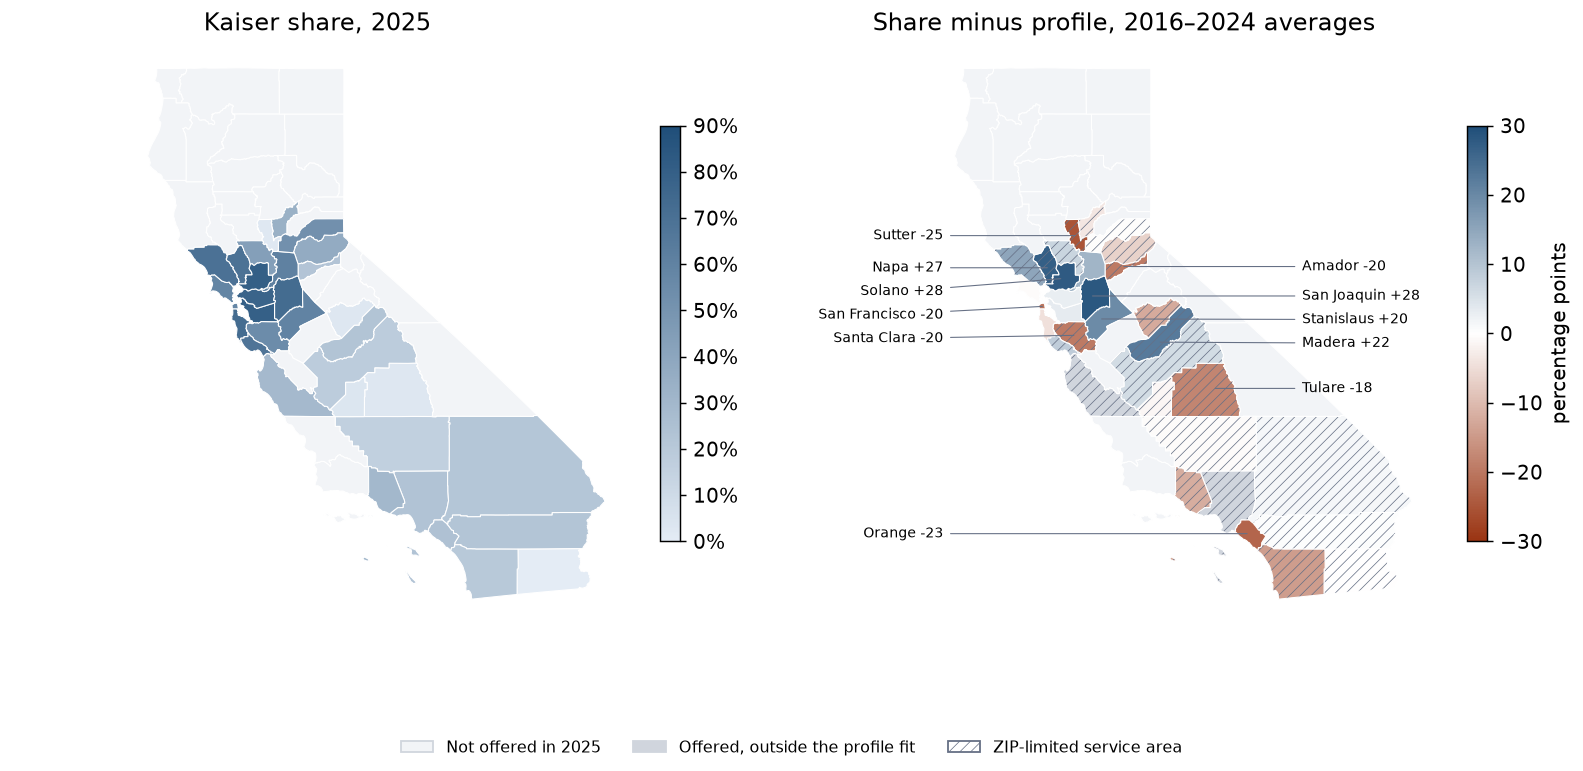

In [3]:
import shapefile
from matplotlib.cm import ScalarMappable
from matplotlib.colors import LinearSegmentedColormap, Normalize, TwoSlopeNorm
from matplotlib.patches import Patch, Polygon

boundaries = shapefile.Reader("../data/raw/census/boundaries/cb_2023_us_county_5m.zip")
X_SCALE = np.cos(np.radians(37.5))
county_rings = {}
for item in boundaries.iterShapeRecords():
    if item.record["STATEFP"] != "06":
        continue
    points = np.array(item.shape.points)
    points[:, 0] *= X_SCALE
    breaks = list(item.shape.parts) + [len(points)]
    county_rings[item.record["GEOID"]] = [points[start:end] for start, end in zip(breaks[:-1], breaks[1:])]

NOT_OFFERED = "#f2f4f7"
OUTSIDE_FIT = "#d0d5dd"
share_colors = LinearSegmentedColormap.from_list("share", ["#e4ecf5", "#1f4e79"])
departure_colors = LinearSegmentedColormap.from_list("departure", ["#9a3412", "#ffffff", "#1f4e79"])
map_2025 = panel.loc[panel["year"] == 2025, ["county_fips", "kp_offered", "kp_market_share", "partial_county"]]
offered_2025 = map_2025[map_2025["kp_offered"]]
share_norm = Normalize(0, np.ceil(offered_2025["kp_market_share"].max() * 10) / 10)
limit = np.ceil(departures["departure_pp"].abs().max() / 5) * 5
departure_norm = TwoSlopeNorm(vcenter=0, vmin=-limit, vmax=limit)
share_fill = {
    row.county_fips: share_colors(share_norm(row.kp_market_share)) for row in offered_2025.itertuples()
}
departure_fill = {fips: OUTSIDE_FIT for fips in offered_2025["county_fips"]}
departure_fill.update({
    row.county_fips: departure_colors(departure_norm(row.departure_pp)) for row in departures.itertuples()
})
zip_limited = set(offered_2025.loc[offered_2025["partial_county"].fillna(False).astype(bool), "county_fips"])


def draw_counties(ax, fills, hatched=()):
    for fips, rings in county_rings.items():
        for ring in rings:
            ax.add_patch(Polygon(
                ring,
                closed=True,
                facecolor=fills.get(fips, NOT_OFFERED),
                edgecolor="white",
                linewidth=0.6,
                hatch="////" if fips in hatched else None,
                hatchcolor="#667085",
            ))
    ax.set_aspect("equal")
    ax.autoscale_view()
    ax.axis("off")


def label_point(fips):
    ring = max(county_rings[fips], key=len)
    return ring[:, 0].mean(), ring[:, 1].mean()


def spread_out(heights, gap):
    placed = []
    for height in heights:
        placed.append(min(height, placed[-1] - gap) if placed else height)
    return placed


def label_counties(ax, frame):
    all_points = np.vstack([ring for rings in county_rings.values() for ring in rings])
    columns = {"left": all_points[:, 0].min() - 0.2, "right": -116.6 * X_SCALE}
    anchors = pd.DataFrame(
        [(row.county, row.departure_pp, *label_point(row.county_fips)) for row in frame.itertuples()],
        columns=["county", "departure_pp", "x", "y"],
    )
    anchors["side"] = np.where((anchors["x"] < -121.5 * X_SCALE) | (anchors["y"] < 35), "left", "right")
    for side, group in anchors.groupby("side"):
        group = group.sort_values("y", ascending=False)
        for row, label_y in zip(group.itertuples(), spread_out(group["y"].tolist(), 0.42)):
            ax.annotate(
                f"{row.county} {row.departure_pp:+.0f}",
                xy=(row.x, row.y),
                xytext=(columns[side], label_y),
                ha="right" if side == "left" else "left",
                va="center",
                fontsize=8,
                arrowprops={"arrowstyle": "-", "color": "#667085", "linewidth": 0.6, "shrinkA": 2, "shrinkB": 0},
            )
    ax.set_xlim(all_points[:, 0].min() - 2.4, all_points[:, 0].max() + 0.3)


plt.rcParams["hatch.linewidth"] = 0.4
fig, (share_ax, departure_ax) = plt.subplots(1, 2, figsize=(12.5, 6.4))
draw_counties(share_ax, share_fill)
share_ax.set_title("Kaiser share, 2025")
fig.colorbar(
    ScalarMappable(norm=share_norm, cmap=share_colors),
    ax=share_ax,
    shrink=0.55,
    format=lambda value, _: f"{value:.0%}",
)

draw_counties(departure_ax, departure_fill, hatched=zip_limited)
departure_ax.set_title("Share minus profile, 2016–2024 averages")
fig.colorbar(
    ScalarMappable(norm=departure_norm, cmap=departure_colors),
    ax=departure_ax,
    shrink=0.55,
    label="percentage points",
)
label_counties(departure_ax, departures[departures["flag"].ne("")])
share_ax.set_xlim(departure_ax.get_xlim())
fig.legend(
    [
        Patch(facecolor=NOT_OFFERED, edgecolor="#d0d5dd"),
        Patch(facecolor=OUTSIDE_FIT, edgecolor="#d0d5dd"),
        Patch(facecolor="white", edgecolor="#667085", hatch="////"),
    ],
    ["Not offered in 2025", "Offered, outside the profile fit", "ZIP-limited service area"],
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=9,
)
fig.tight_layout(rect=(0, 0.04, 1, 1))

## Does share follow a county's own changes?

The profile compares counties with each other. The check here holds each county fixed and asks whether share moved when that county's own uninsured rate, unemployment, or benchmark premium moved, with year effects absorbing anything every county shared. The sample is every offered county-year in 2016–2024 with a premium. Standard errors are clustered by county.

Population barely moves within a county over nine years, so its within-county estimate carries almost no information.


In [4]:
county_years = offered.dropna(subset=["kp_market_share"] + FOUR_TERMS).copy()
within_model = smf.ols(
    FOUR_FORMULA + " + C(county_fips) + C(year)",
    data=county_years,
).fit(cov_type="cluster", cov_kwds={"groups": county_years["county_fips"]})

comparison_rows = []
for name in FOUR_TERMS:
    label, unit, scale = TERM_LABELS[name]
    between_low, between_high = profile_model.conf_int().loc[name] * scale
    within_low, within_high = within_model.conf_int().loc[name] * scale
    comparison_rows.append({
        "term": label,
        "unit": unit,
        "between counties": (
            f"{profile_model.params[name] * scale:.1f} ({between_low:.1f}, {between_high:.1f})"
        ),
        "between p": format_p(profile_model.pvalues[name]),
        "within a county": (
            f"{within_model.params[name] * scale:.1f} ({within_low:.1f}, {within_high:.1f})"
        ),
        "within p": format_p(within_model.pvalues[name]),
    })
display(HTML(pd.DataFrame(comparison_rows).to_html(index=False)))

within_rows = []
for column, label in [
    ("kp_market_share", "Kaiser share"),
    ("uninsured_rate", "Uninsured rate"),
    ("unemployment_rate", "Unemployment rate"),
    ("benchmark_silver_premium", "Benchmark Silver premium"),
]:
    year_adjusted = county_years[column] - county_years.groupby("year")[column].transform("mean")
    within = year_adjusted - year_adjusted.groupby(county_years["county_fips"]).transform("mean")
    within_rows.append({
        "measure": label,
        "share of variation within a county": f"{within.var() / year_adjusted.var():.0%}",
    })
display(Markdown("**How much of each measure varies inside a county, after removing statewide year changes**"))
display(HTML(pd.DataFrame(within_rows).to_html(index=False)))

share_within = within_rows[0]["share of variation within a county"]
benchmark_within = within_model.params["benchmark_silver_premium"] * 1000
benchmark_between = profile_model.params["benchmark_silver_premium"] * 1000
display(Markdown(
    f"Only **{share_within}** of the variation in Kaiser share, after statewide year changes, happens inside a county. "
    f"County-years: **{int(within_model.nobs)}** across **{county_years['county_fips'].nunique()}** counties. "
    f"Within a county, the benchmark premium keeps its direction at **{benchmark_within:.1f}** points per $10, "
    f"against **{benchmark_between:.1f}** between counties. "
    f"The uninsured rate and unemployment do not keep their between-county direction: "
    f"**{within_model.params['uninsured_rate'] * 100:+.1f}** and "
    f"**{within_model.params['unemployment_rate'] * 100:+.1f}** points per percentage point, "
    "with intervals that include zero. "
    "The profile describes where Kaiser is strong. Of the four terms, only the benchmark premium also tracks share over time inside a county."
))


term,unit,between counties,between p,within a county,within p
Population,per doubling,"5.9 (2.3, 9.5)",0.001,"3.7 (-38.6, 46.1)",0.863
Uninsured rate,per percentage point,"-5.0 (-10.0, -0.1)",0.047,"0.7 (-1.2, 2.5)",0.468
Unemployment rate,per percentage point,"-1.5 (-3.0, -0.1)",0.042,"1.2 (-0.0, 2.5)",0.054
Benchmark Silver premium,per $10,"1.5 (0.2, 2.8)",0.024,"0.6 (0.2, 0.9)",0.002


**How much of each measure varies inside a county, after removing statewide year changes**

measure,share of variation within a county
Kaiser share,3%
Uninsured rate,11%
Unemployment rate,3%
Benchmark Silver premium,11%


Only **3%** of the variation in Kaiser share, after statewide year changes, happens inside a county. County-years: **278** across **31** counties. Within a county, the benchmark premium keeps its direction at **0.6** points per $10, against **1.5** between counties. The uninsured rate and unemployment do not keep their between-county direction: **+0.7** and **+1.2** points per percentage point, with intervals that include zero. The profile describes where Kaiser is strong. Of the four terms, only the benchmark premium also tracks share over time inside a county.

## Monterey against the Santa Cruz opening

Santa Cruz entered Kaiser's individual-market service area in 2017. Monterey entered in 2025. Both service areas are ZIP-limited. Santa Cruz is the only other county that opened inside the data, so its path is the closest available reference for what Monterey's next years could look like.

Conditions are set against the median offered county in the opening year, because premiums and the uninsured rate shifted statewide between 2017 and 2025. Monterey's socioeconomic values are 2024, the latest year available.


**Kaiser share (%) by year since the service area opened.** Year 0 is the opening year.

county,years since opening,Monterey,Santa Cruz
,-1,0.9,0.1
,0,29.1,41.0
,1,,55.6
,2,,59.9
,3,,66.8
,4,,66.7
,5,,63.5
,6,,60.8
,7,,64.0
,8,,68.2


county,opening year,first-year share,first-year enrollment,benchmark vs footprint median,uninsured vs footprint median,unemployment vs footprint median,carriers
Santa Cruz,2017,41%,"4,570",$417 vs $408,8.3% vs 9.2%,5.7% vs 4.8%,4
Monterey,2025,29%,"4,940",$744 vs $588,9.6% vs 5.7%,7.3% vs 5.1%,3


Santa Cruz reached **41%** in its opening year, **56%** in the second, and **60%** in the third, then held near **65%**. Monterey opened at **29%**. Santa Cruz opened with an uninsured rate below the footprint median and unemployment about a point above it. Monterey opened with an uninsured rate about four points above the median and unemployment about two points above, which is the profile of the below-median counties, and with a benchmark well above the footprint median. Worth tracking for Monterey in 2026 and 2027: whether share keeps rising the way Santa Cruz's did in its second and third years, whether Kaiser's ZIP list in Monterey widens, and where Monterey's benchmark sits against Santa Cruz's, since the two shared a benchmark in 2025.

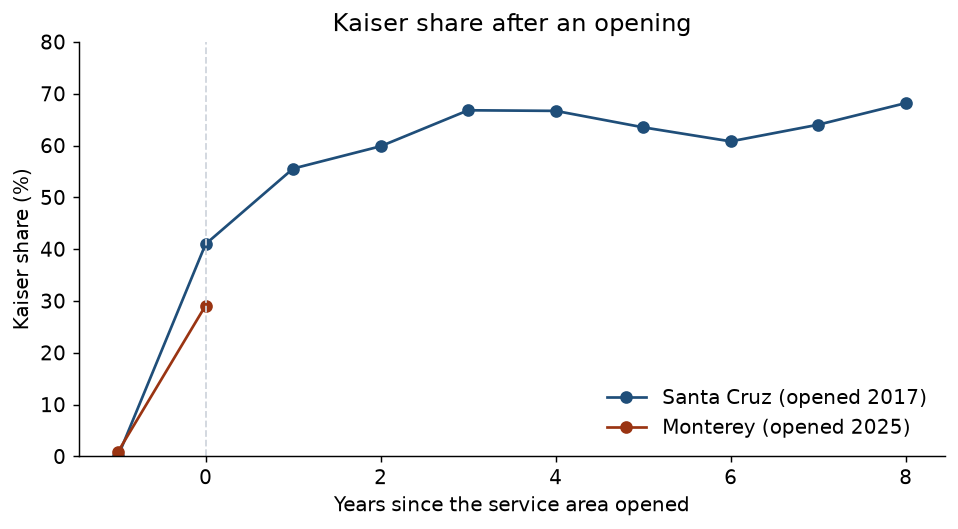

In [5]:
OPENINGS = {"Santa Cruz": 2017, "Monterey": 2025}
paths = []
for name, opening_year in OPENINGS.items():
    rows = panel[panel["county"].eq(name) & panel["kp_market_share"].notna()].copy()
    rows["years_since_opening"] = rows["year"] - opening_year
    paths.append(rows[rows["years_since_opening"] >= -1])
paths = pd.concat(paths)

path_view = paths.pivot_table(
    index="years_since_opening",
    columns="county",
    values="kp_market_share",
)
path_view = (path_view * 100).round(1)
path_view.index.name = "years since opening"
display(Markdown("**Kaiser share (%) by year since the service area opened.** Year 0 is the opening year."))
display(HTML(path_view.reset_index().fillna("").to_html(index=False)))


def opening_conditions(name, opening_year, socio_year):
    row = panel[panel["county"].eq(name) & panel["year"].eq(opening_year)].iloc[0]
    socio_row = panel[panel["county"].eq(name) & panel["year"].eq(socio_year)].iloc[0]
    peers = panel[panel["kp_offered"] & panel["year"].eq(opening_year) & ~panel["county"].isin(OPENINGS)]
    peers_socio = panel[
        panel["county_fips"].isin(peers["county_fips"]) & panel["year"].eq(socio_year)
    ]
    return {
        "county": name,
        "opening year": opening_year,
        "first-year share": f"{row['kp_market_share']:.0%}",
        "first-year enrollment": f"{row['kp_enrollment']:,.0f}",
        "benchmark vs footprint median": (
            f"${row['benchmark_silver_premium']:,.0f} vs ${peers['benchmark_silver_premium'].median():,.0f}"
        ),
        "uninsured vs footprint median": (
            f"{socio_row['uninsured_rate']:.1f}% vs {peers_socio['uninsured_rate'].median():.1f}%"
        ),
        "unemployment vs footprint median": (
            f"{socio_row['unemployment_rate']:.1f}% vs {peers_socio['unemployment_rate'].median():.1f}%"
        ),
        "carriers": int(row["carrier_count"]),
    }


conditions = pd.DataFrame([
    opening_conditions("Santa Cruz", 2017, 2017),
    opening_conditions("Monterey", 2025, 2024),
])
display(HTML(conditions.to_html(index=False)))

santa_cruz = (
    paths[paths["county"].eq("Santa Cruz")]
    .set_index("years_since_opening")["kp_market_share"]
    .sort_index()
)
monterey_first = paths[paths["county"].eq("Monterey") & paths["years_since_opening"].eq(0)]["kp_market_share"].iloc[0]
display(Markdown(
    f"Santa Cruz reached **{santa_cruz.loc[0]:.0%}** in its opening year, **{santa_cruz.loc[1]:.0%}** in the second, "
    f"and **{santa_cruz.loc[2]:.0%}** in the third, then held near **{santa_cruz.loc[3:].mean():.0%}**. "
    f"Monterey opened at **{monterey_first:.0%}**. "
    "Santa Cruz opened with an uninsured rate below the footprint median and unemployment about a point above it. "
    "Monterey opened with an uninsured rate about four points above the median and unemployment about two points above, "
    "which is the profile of the below-median counties, and with a benchmark well above the footprint median. "
    "Worth tracking for Monterey in 2026 and 2027: whether share keeps rising the way Santa Cruz's did in its second and third years, "
    "whether Kaiser's ZIP list in Monterey widens, and where Monterey's benchmark sits against Santa Cruz's, since the two shared a benchmark in 2025."
))

fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, color in [("Santa Cruz", "#1f4e79"), ("Monterey", "#9a3412")]:
    series = paths[paths["county"].eq(name)].sort_values("years_since_opening")
    ax.plot(
        series["years_since_opening"],
        series["kp_market_share"] * 100,
        marker="o",
        color=color,
        label=f"{name} (opened {OPENINGS[name]})",
    )
ax.axvline(0, color="#d0d5dd", linestyle="--", linewidth=1)
ax.set_xlabel("Years since the service area opened")
ax.set_ylabel("Kaiser share (%)")
ax.set_ylim(0, 80)
ax.set_title("Kaiser share after an opening")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()


## Counties Kaiser does not offer

Each county outside the 2025 footprint is matched to offered counties on 2024 population, uninsured rate, and unemployment, each scaled by its spread across offered counties. The benchmark premium is shown beside the match and left out of it. Almost every county outside the footprint is priced above the highest benchmark in any offered county, so including it would match on a premium level the footprint does not contain. Monterey is an opening, so it is not a reference county.

Similar is relative. The distance column is set against how close offered counties are to each other. Close is within the distance that three quarters of offered counties have to their own nearest neighbor. Loose is within the distance nine in ten have. Outside is beyond that. A resemblance says what kind of Kaiser county this looks like on these measures. It does not account for Kaiser's medical offices, hospitals, or provider network, which is what decides whether a service area is possible.


In [6]:
current = panel.loc[panel["year"] == 2025, [
    "county_fips", "county", "kp_offered", "kp_market_share", "kp_enrollment",
    "total_marketplace_enrollment", "benchmark_silver_premium",
]].merge(
    panel.loc[panel["year"] == 2024, ["county_fips", "population_total", "uninsured_rate", "unemployment_rate"]],
    on="county_fips",
)
current["log_population"] = np.log(current["population_total"])
MATCH_TERMS = ["log_population", "uninsured_rate", "unemployment_rate"]

reference = current[current["kp_offered"] & current["county"].ne("Monterey")].reset_index(drop=True)
center = reference[MATCH_TERMS].mean()
spread = reference[MATCH_TERMS].std(ddof=0)
reference_z = ((reference[MATCH_TERMS] - center) / spread).to_numpy()

own_distances = []
for index in range(len(reference_z)):
    gaps = np.sqrt(((reference_z - reference_z[index]) ** 2).sum(axis=1))
    gaps[index] = np.inf
    own_distances.append(gaps.min())
close_cutoff = float(np.quantile(own_distances, 0.75))
loose_cutoff = float(np.quantile(own_distances, 0.9))

candidates = current[~current["kp_offered"]].copy()
candidate_z = ((candidates[MATCH_TERMS] - center) / spread).to_numpy()
screen_rows = []
for row, values in zip(candidates.itertuples(), candidate_z):
    gaps = np.sqrt(((reference_z - values) ** 2).sum(axis=1))
    order = np.argsort(gaps)
    nearest = reference.iloc[order[0]]
    second = reference.iloc[order[1]]
    distance = float(gaps[order[0]])
    if distance <= close_cutoff:
        match = "Close"
    elif distance <= loose_cutoff:
        match = "Loose"
    else:
        match = "Outside"
    screen_rows.append({
        "county": row.county,
        "market_2025": row.total_marketplace_enrollment,
        "kaiser_residents_2025": row.kp_enrollment,
        "population_2024": row.population_total,
        "uninsured_2024": row.uninsured_rate,
        "unemployment_2024": row.unemployment_rate,
        "benchmark_2025": row.benchmark_silver_premium,
        "nearest": nearest["county"],
        "nearest_share_2025": nearest["kp_market_share"],
        "second": second["county"],
        "second_share_2025": second["kp_market_share"],
        "distance": distance,
        "match": match,
    })
screen = pd.DataFrame(screen_rows).sort_values("market_2025", ascending=False).reset_index(drop=True)

screen_view = pd.DataFrame({
    "county": screen["county"],
    "market_2025": screen["market_2025"].map(lambda value: f"{value:,.0f}"),
    "kaiser_residents_2025": screen["kaiser_residents_2025"].map(lambda value: f"{value:,.0f}"),
    "uninsured": screen["uninsured_2024"].map(lambda value: f"{value:.1f}%"),
    "unemployment": screen["unemployment_2024"].map(lambda value: f"{value:.1f}%"),
    "population": screen["population_2024"].map(lambda value: f"{value:,.0f}"),
    "benchmark": screen["benchmark_2025"].map(lambda value: f"${value:,.0f}"),
    "most similar offered county": [
        f"{row.nearest} ({row.nearest_share_2025:.0%})" for row in screen.itertuples()
    ],
    "next most similar": [
        f"{row.second} ({row.second_share_2025:.0%})" for row in screen.itertuples()
    ],
    "distance": screen["distance"].map(lambda value: f"{value:.2f}"),
    "match": screen["match"],
})
display(Markdown(
    f"Close is a distance of **{close_cutoff:.2f}** or less. Loose is **{loose_cutoff:.2f}** or less. "
    "Kaiser residents are Covered California members living in the county with a Kaiser plan, usually near a service-area border. "
    "Share in parentheses is the similar county's 2025 Kaiser share."
))
display(HTML(screen_view.to_html(index=False)))

larger = screen[screen["market_2025"] >= 5000]
benchmark_range = (
    reference["benchmark_silver_premium"].min(),
    reference["benchmark_silver_premium"].max(),
)
above_range = screen[screen["benchmark_2025"] > benchmark_range[1]]


def match_phrase(match):
    return "an outside match" if match == "Outside" else f"a {match.lower()} match"


display(Markdown(
    f"**{len(larger)} counties** outside the footprint had at least 5,000 Covered California members in 2025. "
    + " ".join(
        f"{row.county} ({row.market_2025:,.0f}) most resembles {row.nearest} "
        f"({row.nearest_share_2025:.0%} Kaiser share), {match_phrase(row.match)}."
        for row in larger.itertuples()
    )
    + f" The benchmark in offered counties runs from ${benchmark_range[0]:,.0f} to ${benchmark_range[1]:,.0f}. "
    f"**{len(above_range)} of {len(screen)}** counties outside the footprint are priced above that range."
))


Close is a distance of **0.66** or less. Loose is **0.87** or less. Kaiser residents are Covered California members living in the county with a Kaiser plan, usually near a service-area border. Share in parentheses is the similar county's 2025 Kaiser share.

county,market_2025,kaiser_residents_2025,uninsured,unemployment,population,benchmark,most similar offered county,next most similar,distance,match
Santa Barbara,"22,350",100,8.7%,4.5%,"443,701",$660,Ventura (30%),San Bernardino (22%),1.05,Outside
San Luis Obispo,"17,220",70,5.7%,4.0%,"281,555",$660,Napa (69%),Sonoma (70%),0.54,Close
Merced,"17,110",180,8.1%,9.8%,"290,201",$832,Tulare (3%),Kings (4%),0.44,Close
Butte,"9,410",70,6.4%,5.9%,"207,929",$765,Yuba (34%),Madera (23%),0.74,Loose
Shasta,"9,340",30,6.5%,5.3%,"181,436",$765,Napa (69%),Yuba (34%),0.76,Loose
Nevada,"8,860",130,5.3%,4.5%,"102,481",$765,Napa (69%),Yolo (44%),0.40,Close
Humboldt,"7,470",10,4.9%,5.1%,"134,541",$765,Yolo (44%),Santa Cruz (68%),0.39,Close
Mendocino,"4,920",70,7.7%,5.6%,"90,244",$765,Madera (23%),Yuba (34%),0.82,Loose
Tuolumne,"2,680",50,5.3%,5.2%,"54,498",$765,Amador (23%),Napa (69%),0.34,Close
Tehama,"2,560",10,6.6%,6.2%,"65,167",$765,Yuba (34%),Sutter (2%),0.32,Close


**7 counties** outside the footprint had at least 5,000 Covered California members in 2025. Santa Barbara (22,350) most resembles Ventura (30% Kaiser share), an outside match. San Luis Obispo (17,220) most resembles Napa (69% Kaiser share), a close match. Merced (17,110) most resembles Tulare (3% Kaiser share), a close match. Butte (9,410) most resembles Yuba (34% Kaiser share), a loose match. Shasta (9,340) most resembles Napa (69% Kaiser share), a loose match. Nevada (8,860) most resembles Napa (69% Kaiser share), a close match. Humboldt (7,470) most resembles Yolo (44% Kaiser share), a close match. The benchmark in offered counties runs from $412 to $744. **23 of 25** counties outside the footprint are priced above that range.

## What this points to

**Shortfalls worth explaining.** The counties well below their profile are not all ZIP-limited. Orange, the largest gap in members, is a whole-county service area that the profile places near 40% share and that holds under 20%. Holding Kaiser's Northern and Southern California regions constant narrows Orange's gap from 23 to 16 points, still past one residual standard error. A ZIP-level view of where Kaiser's members live inside these counties, and of competing carriers there, is the next question.

**Counties that outperform.** Solano, San Joaquin, Napa, Madera, and Stanislaus hold more share than their conditions imply. They are worth studying as what is going right, not as targets.

**Conditions describe the map more than they move share.** Within a county, only the benchmark premium tracks share over time. A future study with more years, or with openings and service-area changes as events, is what could say whether any of these conditions act as levers.

**Openings.** Santa Cruz is the reference for Monterey. Monterey's second and third years in 2026 and 2027 will show whether it follows that path from a lower starting point.

**Outside the footprint.** Among the larger markets, San Luis Obispo and Nevada look most like Napa, and Humboldt like Yolo, on population, uninsurance, and unemployment. Merced looks like Tulare and Kings, where Kaiser holds a few percent. San Luis Obispo's benchmark sits inside the footprint's range. Nevada, Humboldt, and Merced are priced above it, so for them price is a difference this screen sets aside. Whether any resemblance matters depends on provider network and service-area feasibility, which this data does not contain.

Limits carried from earlier notebooks: offered includes ZIP-limited service areas, the premium is an age-40 individual rate, Los Angeles has no county premium, and every comparison here is across counties within one state's Marketplace from 2016 to 2025.
